<a href="https://colab.research.google.com/github/dahlia1384/ENGR418_TeamProject8/blob/main/UCI_HAR_Dataset_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Step 0: Linking Google Drive ('cuz I'm an Idiot)**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# **1. Preliminary Analysis of the UCI-HAR 2012 Dataset**

The preliminary analysis should answer four practical questions before modelling:
1. Is the dataset loaded correctly?
2. Are the activity classes and participants adequately represented?
3. How redundant are the 561 features?
4. Does the data suggest that dimensionality reduction is justified?

Its purpose is to verify the data and justify the modelling design, not to select the configuration that performs best on the official test set. We are using the official training set only for these decisions.


**Important Note:** Gemini did help me code this, mainly because syntax can be incredibly annoying, *especially* in Python and with pathing.


# **1.1. Loading and Assembling the Training Data**

The official UCI-HAR folder contains separate files for features, activity labels, and participant identifiers.

In [ ]:
### Some Inportant Imports Needed
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler as stsc
from sklearn.decomposition import PCA
from sklearn.model_selection import StratifiedGroupKFold as sgk
from sklearn.pipeline import Pipeline as ppl
from sklearn.linear_model import LogisticRegression as logreg
from sklearn.model_selection import GridSearchCV as gsCV

DATA_DIR = Path("/content/drive/MyDrive/human+activity+recognition+using+smartphones/UCI HAR Dataset")

# Feature Descriptions of the Dataset
features = pd.read_csv(DATA_DIR / "features.txt", sep=r"\s+", header=None, names=["feature_id", "feature_name"])

# Adding the feature number becomes some UCI feature names are duplicated
feature_names = [f"f{row.feature_id:03d}_{row.feature_name}" for row in features.itertuples()]

# Training Data
X_train = pd.read_csv(DATA_DIR / "train/X_train.txt", sep=r"\s+", header=None, names=feature_names)
y_train = pd.read_csv(DATA_DIR / "train/y_train.txt", sep=r"\s+", header=None, names=["activity_id"])["activity_id"]
subject_train = pd.read_csv(DATA_DIR / "train/subject_train.txt", sep=r"\s+", header=None, names=["subject_id"])["subject_id"]

# Acitvity_name lookups
activity_labels = pd.read_csv(DATA_DIR / "activity_labels.txt", sep=r"\s+", header=None, names=["activity_id", "activity_name"])
activity_map = dict(zip(activity_labels.activity_id, activity_labels.activity_name))

y_names = y_train.map(activity_map)

# Confirming the expected dimensions
print(X_train.shape)                  # Should have 7,352 datapoints with 561 features
print(y_train.shape[0])               # Should have 7,352 activity labels
print(y_train.nunique())              # Should have 6 unique activity labels
print(subject_train.shape[0])         # Should have 7,352 unique datapoints
print(subject_train.nunique())        # Should have 21 participants

# Added security feature. Adding assertions to detect an incorrectly loaded file.
assert X_train.shape == (7352, 561)
assert y_train.shape[0] == 7352
assert y_train.nunique() == 6
assert subject_train.shape[0] == 7352
assert subject_train.nunique() == 21

(7352, 561)
7352
6
7352
21


The official UCI-HAR training set was loaded successfully. It contained 7,352 observations, each represented by 561 sensor-derived features. Every observation had a corresponding activity label and participant identifier. The training data included six activity classes collected from 21 unique participants.

# **1.2. Checking Data Integrity**


In [ ]:
# Checking for missing values, infinite values, invalid labels, and duplicated observations. Verifying that every feature is numeric.

print("Missing values:", X_train.isna().sum().sum())                  # Should be 0
print("Infinite values:", np.isinf(X_train.to_numpy()).sum())         # Should be 0
print("Duplicate feature rows:", X_train.duplicated().sum())          # Should be 0
print("Activity codes:", sorted(y_train.unique()))                    # Should look like [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
print("Subjects:", sorted(subject_train.unique()))                    # Should look like [np.int64(1), np.int64(3), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(11), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(19), np.int64(21), np.int64(22), np.int64(23), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30)]

non_numeric = X_train.select_dtypes(exclude=np.number).columns
print("Non-numeric columns:", list(non_numeric))                      # Should be empty []

### Do not automatically delete duplicated rows. Because the data consist of windowed sensor measurements, identical or nearly identical observations may be legitimate. Reporting their number first and investigate their labels and participants,
duplicate_mask = X_train.duplicated(keep=False)
duplicate_check = pd.DataFrame({"activity": y_names[duplicate_mask], "subject": subject_train[duplicate_mask]})
print(duplicate_check.head())

Missing values: 0
Infinite values: 0
Duplicate feature rows: 0
Activity codes: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
Subjects: [np.int64(1), np.int64(3), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(11), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(19), np.int64(21), np.int64(22), np.int64(23), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30)]
Non-numeric columns: []
Empty DataFrame
Columns: [activity, subject]
Index: []


No immediate data-integrity issues were identified in the training dataset. The feature matrix contained no missing or infinite values, no non-numeric variables, and no exact duplicate observations. All six expected activity codes were present, and the 21 unique subject identifiers were consistent with the official participant-separated training partition.

# **1.3. Examining the Activity Class Representation**

                    count    percent
activity_id                         
LAYING               1407  19.137650
STANDING             1374  18.688792
SITTING              1286  17.491839
WALKING              1226  16.675734
WALKING_UPSTAIRS     1073  14.594668
WALKING_DOWNSTAIRS    986  13.411317


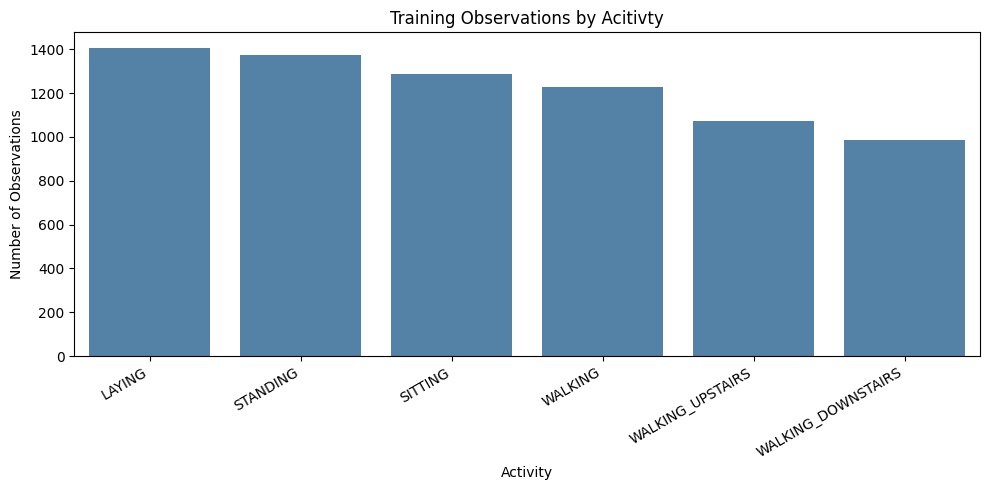

Imbalance ratio/Largest-to-smallest ratio: 1.4269776876267748


In [ ]:
# Determining how many observations belong to each activity.

class_counts = y_names.value_counts()
class_percent = y_names.value_counts(normalize = True).mul(100)
class_summary = pd.DataFrame({"count": class_counts, "percent": class_percent})
print(class_summary)


plt.figure(figsize=(10, 5))
sns.countplot(x = y_names, order = class_counts.index, color = "steelblue")
plt.xticks(rotation = 30, ha = "right")
plt.xlabel("Activity")
plt.ylabel("Number of Observations")
plt.title("Training Observations by Acitivty")
plt.tight_layout()
plt.show()

# Imbalance ratios
# A large imbalance will justify a macro-F1 addition to accuracy calculations.
imbalance_ratio = class_counts.max()/class_counts.min()
print("Imbalance ratio/Largest-to-smallest ratio:", imbalance_ratio)

The training data exhibited mild class imbalance. LAYING was the most represented activity with 1,407 observations (19.14%), while WALKING_DOWNSTAIRS was the least represented with 986 observations (13.41%). The resulting largest-to-smallest class ratio was approximately 1.43:1. Although the imbalance was not severe enough to require resampling, macro-averaged F1-score and class-specific performance measures will be reported alongside accuracy to ensure that performance on the smaller classes is adequately represented.

# **1.4.A. Examining Each Representation by Participant**

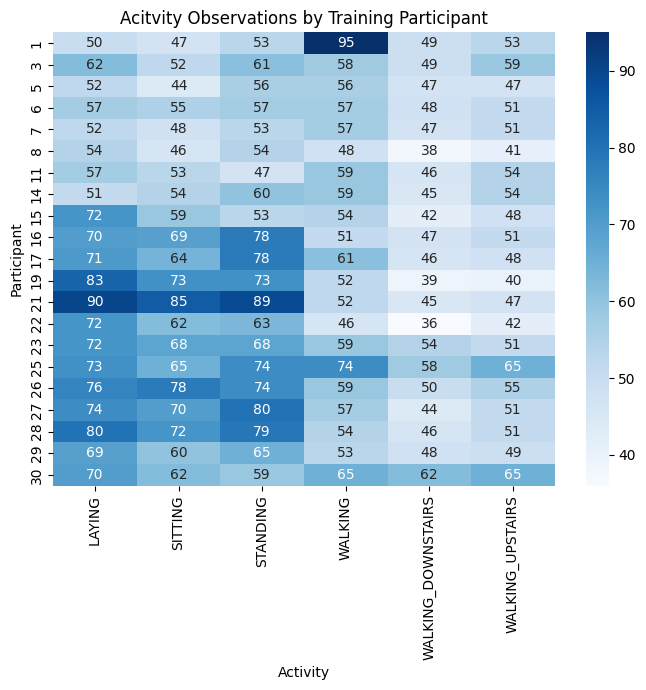

In [ ]:
# The analysis should confirm the following:
#     1. Whether every participant performed every activity;
#     2. Whether some participants contributed substantially more observations;
#     3. Whether particular activites are underrepresented for certain participants.
# The results can support the decision to use participant-grouped cross-validation.
# If observations were randomly divided into folds, measurements from the same person would appear in both training and test data.

subject_activity = pd.crosstab(subject_train, y_names)
#print(subject_activity)

plt.figure(figsize=(7, 7))
sns.heatmap(subject_activity, cmap = "Blues", annot = True, fmt = "d")
plt.xlabel("Activity")
plt.ylabel("Participant")
plt.title("Acitvity Observations by Training Participant")
plt.tight_layout()
plt.show()

Participant contributions were not uniformly distributed across activities. Individual participant–activity combinations contained between 36 and 95 observations, with some participants contributing substantially more observations to particular activities. For example, Participant 1 contributed 95 WALKING observations, while Participant 21 contributed 85–90 observations to the three stationary activities. Nevertheless, all 21 training participants were represented in all six activity classes, and no participant–activity combinations were missing. The observed heterogeneity reinforces the use of participant-grouped cross-validation to prevent observations from the same individual from appearing in both training and validation subsets.

# **1.4.B. Cross-Validation**



Number of folds: 5

Fold 1
Training participants: [np.int64(1), np.int64(3), np.int64(6), np.int64(8), np.int64(11), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(19), np.int64(21), np.int64(23), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30)]
Validation participants: [np.int64(5), np.int64(7), np.int64(22), np.int64(25)]
Participant overlap: []

Fold 2
Training participants: [np.int64(3), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(11), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(22), np.int64(23), np.int64(25), np.int64(26), np.int64(27), np.int64(29), np.int64(30)]
Validation participants: [np.int64(1), np.int64(19), np.int64(21), np.int64(28)]
Participant overlap: []

Fold 3
Training participants: [np.int64(1), np.int64(3), np.int64(5), np.int64(6), np.int64(7), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(19), np.int64(21), np.int64(22), np.int64(25), np.int64(26), np.int64(28), np.i

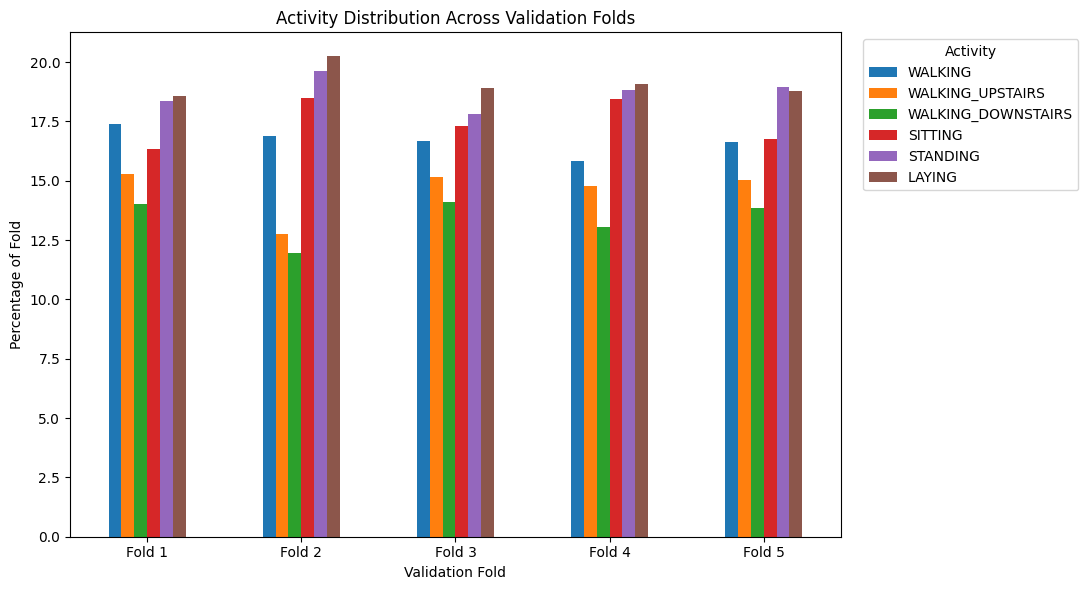

All six activities in every validation fold: PASS
Every participant validated exactly once: PASS
No participant overlap: PASS

Conclusion: The folds satisfy the essential requirements for participant-grouped cross-validation.
Best parameters: {'classifier__C': 1}
Best cross-validation macro-F1: 0.9264
 fold  training_macro_f1  validation_macro_f1  validation_accuracy
    1             0.9989               0.9110               0.9142
    2             0.9984               0.9350               0.9312
    3             0.9967               0.9692               0.9693
    4             0.9989               0.8667               0.8687
    5             0.9969               0.9501               0.9521

Mean validation macro-F1: 0.9264
SD validation macro-F1: 0.0396
Minimum validation macro-F1: 0.8667
Maximum validation macro-F1: 0.9692
Mean training-validation gap: 0.0716
 param_classifier__C  mean_train_macro_f1  mean_test_macro_f1  std_test_macro_f1  mean_test_accuracy  rank_test_macro_f1 

In [ ]:
# Resetting the indices ensures that positional indices returned by scikit-learn correspond correctly to all three datasets.

X_cv = X_train.reset_index(drop=True)
y_cv = y_train.reset_index(drop=True)
groups_cv = subject_train.reset_index(drop=True)

# Convert numeric activity codes to names for readable output
y_name_cv = y_cv.map(activity_map)

activity_order = [activity_map[activity_id] for activity_id in sorted(activity_map)]

assert len(X_cv) == len(y_cv) == len(groups_cv)
assert y_name_cv.notna().all()

# Creating the participant-grouped folds
cv = sgk(n_splits=5, shuffle=True, random_state=42)

cv_splits = list(cv.split(X_cv, y_cv, groups=groups_cv))

print("Number of folds:", len(cv_splits))

# Check participant separation and fold sizes

summary_rows = []
validation_subjects_all = []
fold_assignments = {}

for fold, (train_index, validation_index) in enumerate(cv_splits, start=1):
    train_subjects = sorted(groups_cv.iloc[train_index].unique())
    validation_subjects = sorted(groups_cv.iloc[validation_index].unique())
    overlap = set(train_subjects).intersection(validation_subjects)

    validation_subjects_all.extend(validation_subjects)

    for subject in validation_subjects:
        fold_assignments[int(subject)] = fold

    summary_rows.append({
        "fold": fold,
        "training_rows": len(train_index),
        "validation_rows": len(validation_index),
        "training_subjects": len(train_subjects),
        "validation_subjects": len(validation_subjects),
        "subject_overlap": len(overlap),
        "validation_classes":
            y_cv.iloc[validation_index].nunique()
    })

    print(f"\nFold {fold}")
    print("Training participants:", train_subjects)
    print("Validation participants:", validation_subjects)
    print("Participant overlap:", sorted(overlap))

summary_df = pd.DataFrame(summary_rows)

print("\nCross-validation summary")
print(summary_df.to_string(index=False))

# Verifying that every participant is validated once

validation_frequency = (pd.Series(validation_subjects_all, name="subject_id").value_counts().sort_index())

print("\nNumber of validation appearances per participant")
print(validation_frequency.to_string())

print("\nParticipant-to-fold assignment")
for subject, fold in sorted(fold_assignments.items()):
    print(f"Participant {subject}: Fold {fold}")

assert len(validation_subjects_all) == groups_cv.nunique()
assert set(validation_subjects_all) == set(groups_cv.unique())
assert validation_frequency.eq(1).all()
assert summary_df["subject_overlap"].eq(0).all()
assert summary_df["validation_classes"].eq(6).all()

# Printing activity counts in every validation fold

fold_counts = {}

for fold, (_, validation_index) in enumerate(cv_splits,start=1):
    counts = (y_name_cv.iloc[validation_index].value_counts().reindex(activity_order, fill_value=0))
    fold_counts[f"Fold {fold}"] = counts

fold_count_df = pd.DataFrame(fold_counts)

print("\nActivity counts by validation fold")
print(fold_count_df.to_string())

# Printing activity percentages in every validation fold

fold_percent_df = (fold_count_df.divide(fold_count_df.sum(axis=0), axis=1).multiply(100))

print("\nActivity percentages by validation fold")
print(fold_percent_df.round(2).to_string())

overall_percentage = (y_name_cv.value_counts(normalize=True).reindex(activity_order).multiply(100))

comparison_df = fold_percent_df.copy()
comparison_df.insert(0, "Overall training set", overall_percentage)

print("\nOverall and fold-specific percentages")
print(comparison_df.round(2).to_string())

# Quantifying deviations from the whole distribution

deviation_df = fold_percent_df.subtract(overall_percentage, axis=0)

absolute_deviation_df = deviation_df.abs()

print("\nPercentage-point deviation from overall distribution")
print(absolute_deviation_df.round(2).to_string())

maximum_deviation_by_fold = (absolute_deviation_df.max(axis=0))

print("\nMaximum absolute deviation in each fold")
print(maximum_deviation_by_fold.round(2).to_string())

print("\nLargest deviation across all folds:", round(absolute_deviation_df.to_numpy().max(), 2), "percentage points")

# Visualizing the fold distributions

fold_percent_df.T.plot(kind="bar", figsize=(11, 6))

plt.xlabel("Validation Fold")
plt.ylabel("Percentage of Fold")
plt.title("Activity Distribution Across Validation Folds")
plt.xticks(rotation=0)
plt.legend(title="Activity", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Diagnostic Summary

zero_overlap = summary_df["subject_overlap"].eq(0).all()
all_classes_present = (
    summary_df["validation_classes"].eq(6).all()
)
each_subject_once = validation_frequency.eq(1).all()

print("All six activities in every validation fold:", "PASS" if all_classes_present else "FAIL")

print("Every participant validated exactly once:", "PASS" if each_subject_once else "FAIL")

print("No participant overlap:", "PASS" if zero_overlap else "FAIL")

if zero_overlap and all_classes_present and each_subject_once:
    print("\nConclusion: The folds satisfy the essential requirements for participant-grouped cross-validation.")
else:
    print("\nConclusion: The fold construction requires further investigation.")

# We are going to use the same folds during model tuning.

pipeline = ppl([("scaler", stsc()),("classifier",logreg(max_iter=5000))])

parameter_grid = {"classifier__C": [0.1, 1, 10]}

search = gsCV(estimator=pipeline, param_grid=parameter_grid,
    scoring={
        "macro_f1": "f1_macro",
        "accuracy": "accuracy"
    }, refit="macro_f1", cv=cv_splits, n_jobs=-1, return_train_score=True)

search.fit(X_cv, y_cv)

print("Best parameters:", search.best_params_)
print("Best cross-validation macro-F1:", round(search.best_score_, 4))

best_index = search.best_index_

validation_f1 = np.array([search.cv_results_[f"split{fold}_test_macro_f1"][best_index] for fold in range(5)])

training_f1 = np.array([search.cv_results_[f"split{fold}_train_macro_f1"][best_index] for fold in range(5)])

validation_accuracy = np.array([search.cv_results_[f"split{fold}_test_accuracy"][best_index] for fold in range(5)])

fold_performance = pd.DataFrame({
    "fold": range(1, 6),
    "training_macro_f1": training_f1,
    "validation_macro_f1": validation_f1,
    "validation_accuracy": validation_accuracy
})

print(fold_performance.round(4).to_string(index=False))

print("\nMean validation macro-F1:", round(validation_f1.mean(), 4))
print("SD validation macro-F1:", round(validation_f1.std(ddof=1), 4))
print("Minimum validation macro-F1:", round(validation_f1.min(), 4))
print("Maximum validation macro-F1:", round(validation_f1.max(), 4))
print("Mean training-validation gap:", round(training_f1.mean() - validation_f1.mean(), 4))

# Confirming C = 1 with other regularization strengths

grid_results = pd.DataFrame(search.cv_results_)

comparison = grid_results[[
    "param_classifier__C",
    "mean_train_macro_f1",
    "mean_test_macro_f1",
    "std_test_macro_f1",
    "mean_test_accuracy",
    "rank_test_macro_f1"]].copy()

comparison["generalization_gap"] = (comparison["mean_train_macro_f1"] - comparison["mean_test_macro_f1"])

comparison = comparison.sort_values("rank_test_macro_f1")
print(comparison.round(4).to_string(index=False))

Five-fold stratified group cross-validation was constructed using participant identifiers as groups. Each validation fold contained four or five participants, and no participant appeared in both the training and validation portions of the same fold. All six activities were represented in every validation fold, and each of the 21 training participants appeared in validation exactly once. Activity proportions closely matched those of the complete training set, with a maximum absolute deviation of 1.84 percentage points. The folds were therefore considered suitable for leakage-resistant model selection. Using these folds, the preliminary full-feature Logistic Regression model selected \(C=1\) and achieved a mean cross-validation macro-F1 score of 0.9264.

The full-feature Logistic Regression model achieved a mean grouped cross-validation macro-F1 score of 0.9264, with a standard deviation of 0.0396. Fold-specific scores ranged from 0.8667 to 0.9692, demonstrating that performance varied depending on the participants withheld for validation. Training macro-F1 scores exceeded 0.996 in all folds, producing an average training–validation gap of 0.0716. This indicates that the model fitted the training participants extremely well but generalized less consistently to unseen individuals. Accuracy closely matched macro-F1 across all folds, suggesting that the observed variability was not primarily caused by class imbalance. These findings support investigating whether feature reduction and stronger regularization can improve cross-participant consistency while reducing model complexity.

# **1.5. Examining Feature Distributions and Variability**

                         count      mean       std       min       25%  \
f001_tBodyAcc-mean()-X  7352.0  0.274488  0.070261 -1.000000  0.262975   
f002_tBodyAcc-mean()-Y  7352.0 -0.017695  0.040811 -1.000000 -0.024863   
f003_tBodyAcc-mean()-Z  7352.0 -0.109141  0.056635 -1.000000 -0.120993   
f004_tBodyAcc-std()-X   7352.0 -0.605438  0.448734 -1.000000 -0.992754   
f005_tBodyAcc-std()-Y   7352.0 -0.510938  0.502645 -0.999873 -0.978129   

                             50%       75%       max  variance      skew  \
f001_tBodyAcc-mean()-X  0.277193  0.288461  1.000000  0.004937 -3.448322   
f002_tBodyAcc-mean()-Y -0.017219 -0.010783  1.000000  0.001665 -0.402995   
f003_tBodyAcc-mean()-Z -0.108676 -0.097794  1.000000  0.003208  1.784469   
f004_tBodyAcc-std()-X  -0.946196 -0.242813  1.000000  0.201363  0.677430   
f005_tBodyAcc-std()-Y  -0.851897 -0.034231  0.916238  0.252652  0.405892   

                          kurtosis     range  
f001_tBodyAcc-mean()-X   50.911391  2.000000  
f002

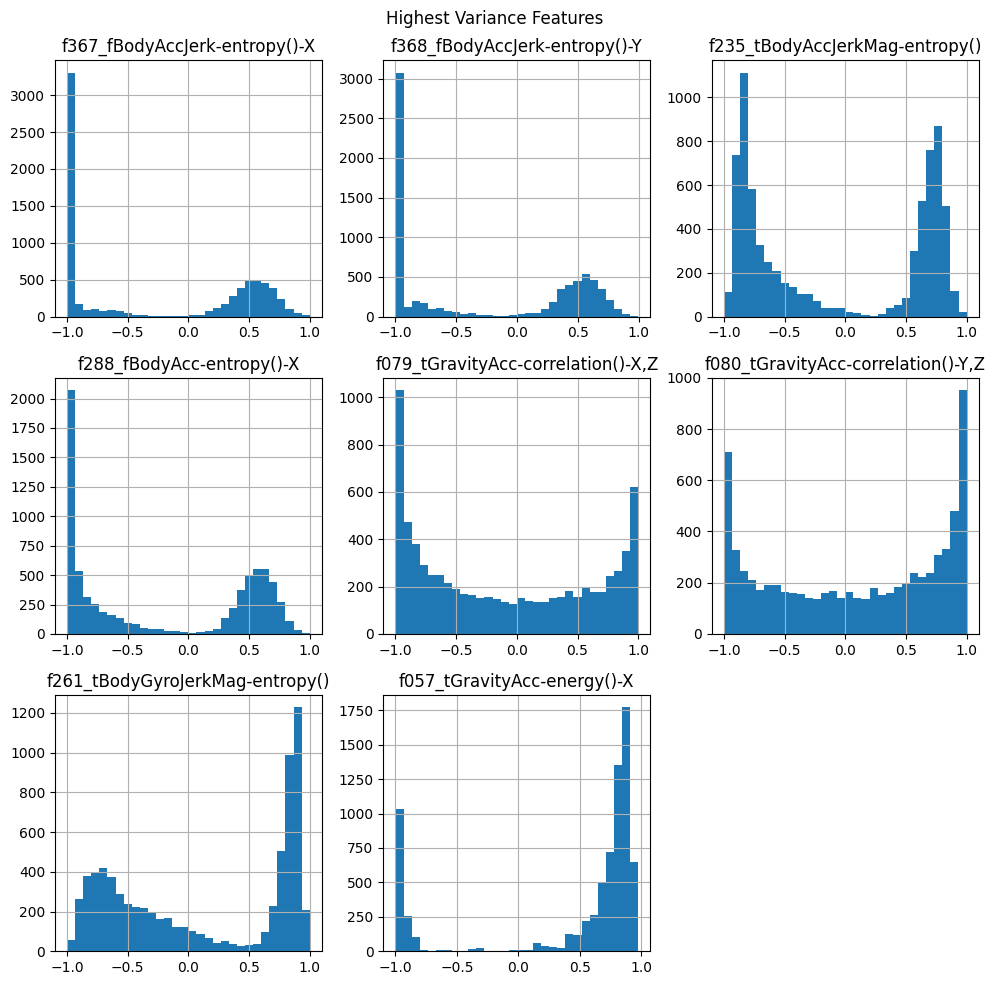

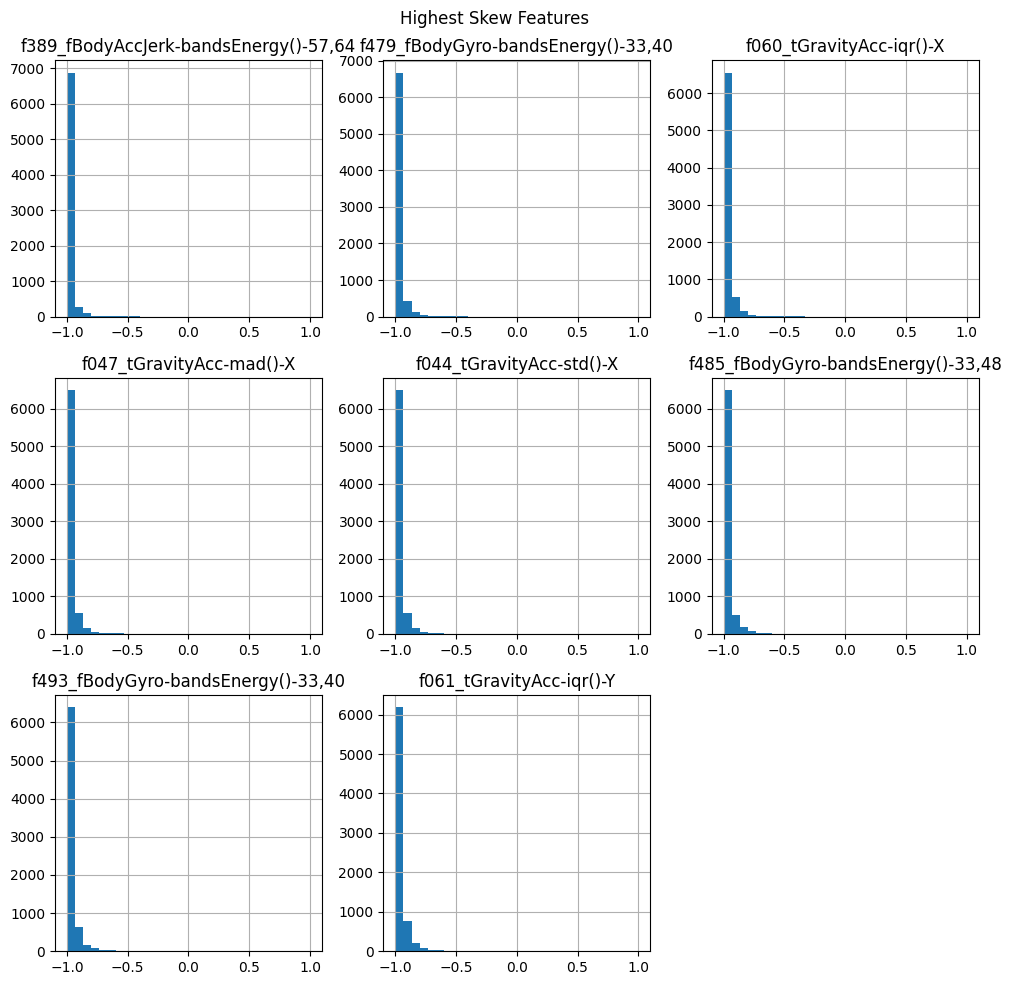

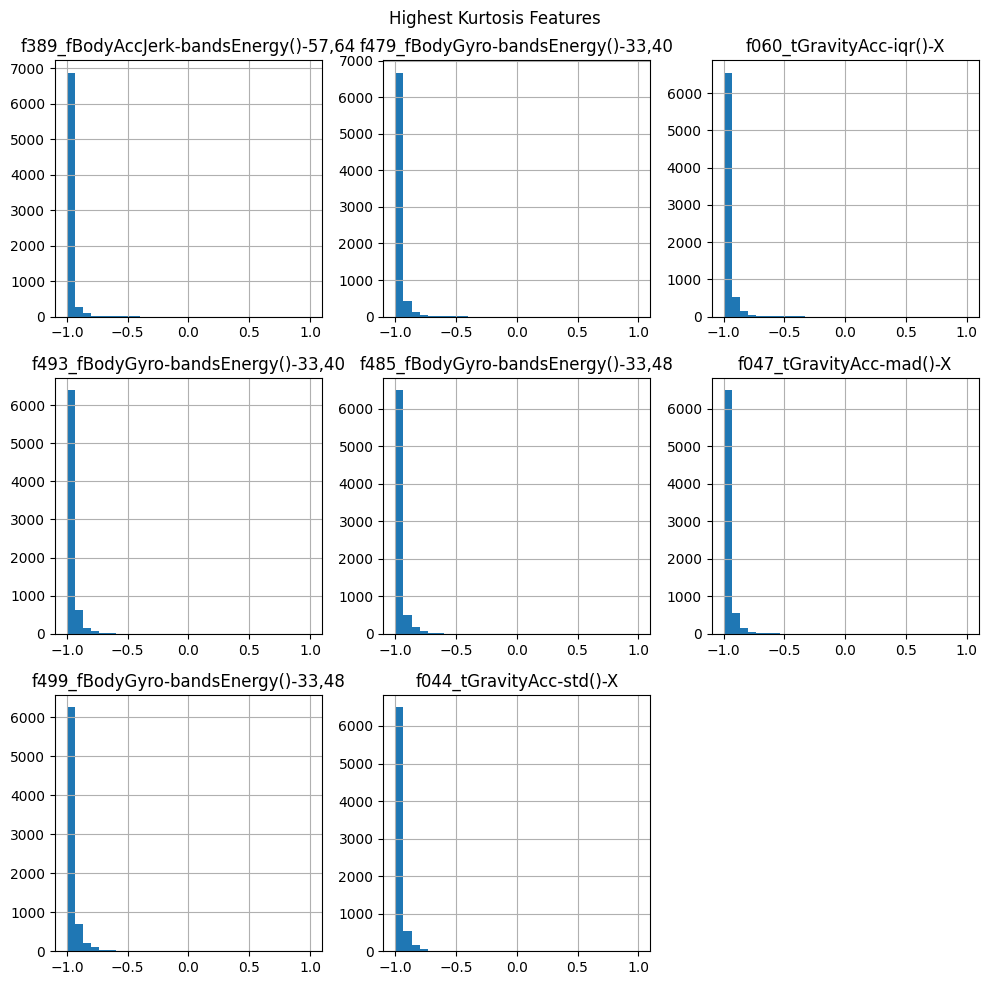

In [ ]:
# Descriptive Statistics:

feature_summary = X_train.describe().T
feature_summary["variance"] = X_train.var()
feature_summary["skew"] = X_train.skew()
feature_summary["kurtosis"] = X_train.kurtosis()
feature_summary["range"] = (feature_summary["max"] - feature_summary["min"])

print(feature_summary.head())

# Indentiying constant or nealry constant features:
const_features = feature_summary[feature_summary["variance"] == 0]
near_const_features = feature_summary[feature_summary["variance"] < 0.00001]

print("Constant Features: ", len(const_features))
print("Nearly Constant Features: ", len(near_const_features))

print("Overall Minimum: ", X_train.min().min())
print("Overall Maximum: ", X_train.max().max())

# The UCI-HAR features were normalized by the dataset developers and should fall ebtween -1 and 1.
# Values outside the expected range should be investigated.

# Not using all 561 features to make the distribution plot readable.
highest_variance = (X_train.var().sort_values(ascending=False).head(8).index)
highest_skew = (X_train.skew().sort_values(ascending=False).head(8).index)
highest_kurtosis = (X_train.kurtosis().sort_values(ascending=False).head(8).index)

X_train[highest_variance].hist(bins = 30, figsize = (10, 10))
plt.suptitle("Highest Variance Features")
plt.tight_layout()
plt.show()

X_train[highest_skew].hist(bins = 30, figsize = (10, 10))
plt.suptitle("Highest Skew Features")
plt.tight_layout()
plt.show()

X_train[highest_kurtosis].hist(bins = 30, figsize = (10, 10))
plt.suptitle("Highest Kurtosis Features")
plt.tight_layout()
plt.show()


All 561 input features exhibited nonzero variance, and no variables fell below the selected near-zero variance threshold of \(10^{-5}\). Feature values remained within the expected normalized interval of \([-1,1]\). Nevertheless, the variables differed substantially in variance and distributional shape. Several high-variance entropy, energy, and correlation features exhibited bimodal or boundary-concentrated distributions, while some variables displayed substantial skewness and excess kurtosis. These characteristics were not treated as data errors because the observations remained within the documented feature bounds and may represent meaningful differences among activities or participants. No features were removed during preliminary screening; redundancy and predictive usefulness will instead be evaluated through correlation analysis, PCA, feature selection, and participant-grouped cross-validation.

# **1.6. Quantifying Correlation and Feature Redundancy**

|r| > 0.9: 8206 feature pairs
|r| > 0.95: 2281 feature pairs
|r| > 0.99: 207 feature pairs
                               feature_1                        feature_2  \
156556      f529_fBodyBodyGyroMag-mean()      f534_fBodyBodyGyroMag-sma()   
155373           f503_fBodyAccMag-mean()           f508_fBodyAccMag-sma()   
105403          f240_tBodyGyroMag-mean()          f245_tBodyGyroMag-sma()   
109498      f253_tBodyGyroJerkMag-mean()      f258_tBodyGyroJerkMag-sma()   
95667        f211_tBodyAccMag-arCoeff()2   f224_tGravityAccMag-arCoeff()2   
95316        f210_tBodyAccMag-arCoeff()1   f223_tGravityAccMag-arCoeff()1   
92472             f202_tBodyAccMag-std()        f215_tGravityAccMag-std()   
92104            f201_tBodyAccMag-mean()           f206_tBodyAccMag-sma()   
156049   f516_fBodyBodyAccJerkMag-mean()   f521_fBodyBodyAccJerkMag-sma()   
156894  f542_fBodyBodyGyroJerkMag-mean()  f547_fBodyBodyGyroJerkMag-sma()   
92117            f201_tBodyAccMag-mean()        f219_tGravityA

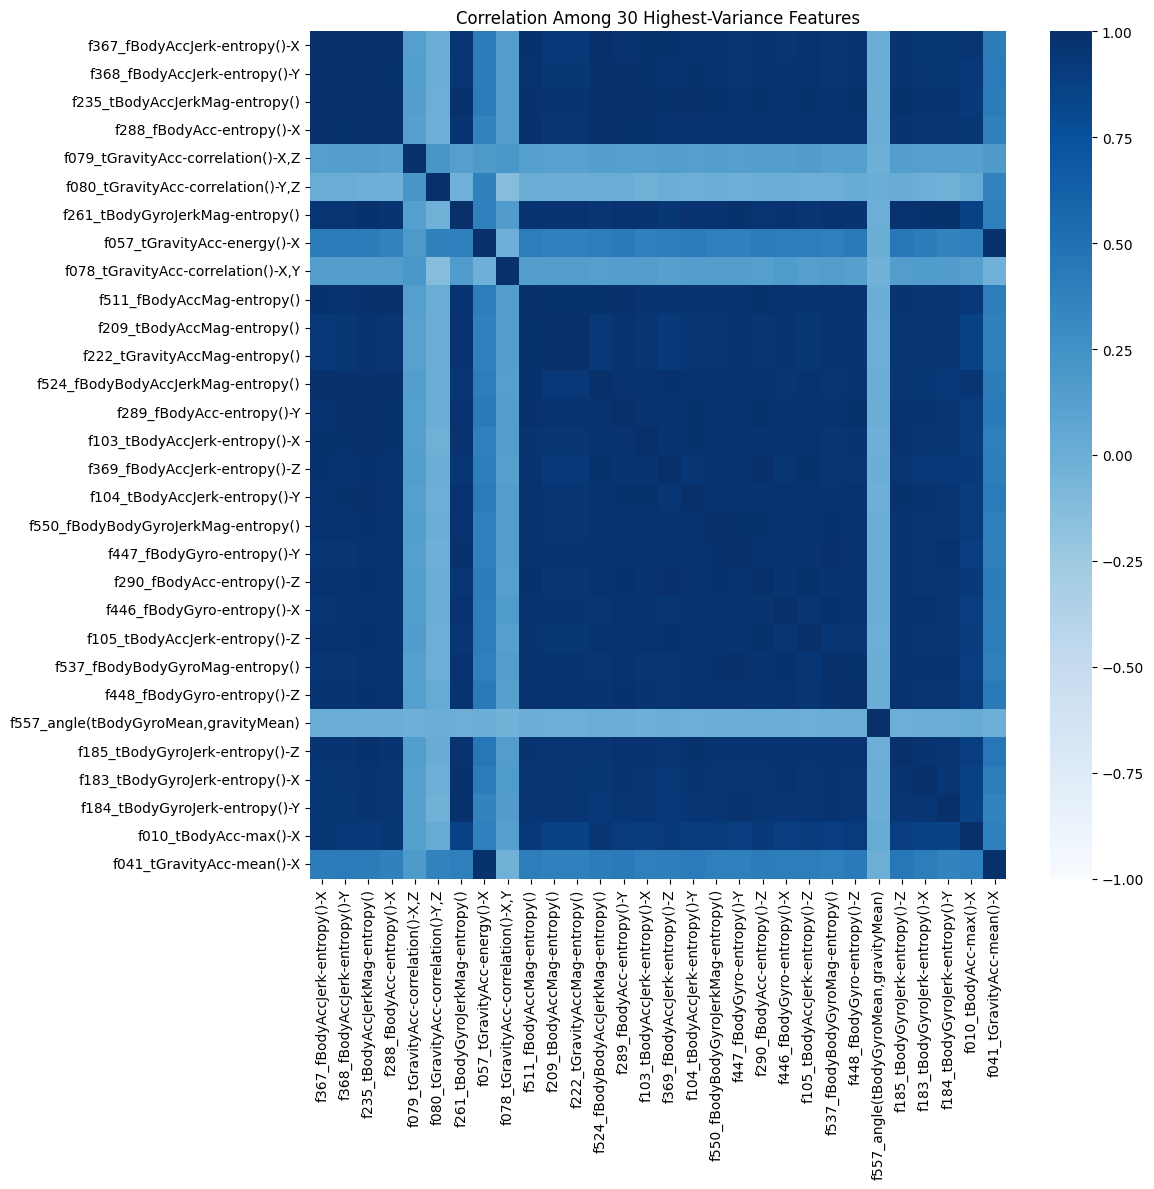

In [ ]:
# Checking to see if UC-HAR variables contain similar information.

# Calculating thr correlation matrix
corr_matrix = X_train.corr().abs()
upp_triangle = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k = 1).astype(bool))


# Countiing highly correlated feature pairs
for threshold in [0.90, 0.95, 0.99]:
  pair_count = (upp_triangle > threshold).sum().sum()
  print(f"|r| > {threshold}: {pair_count} feature pairs")

# Identifying features involved in correlations above 0.95
high_corr_pairs = (upp_triangle.stack().reset_index())
high_corr_pairs.columns = ["feature_1", "feature_2", "absolute_correlation"]
high_corr_pairs = high_corr_pairs[high_corr_pairs["absolute_correlation"] > 0.95].sort_values("absolute_correlation", ascending = False)
print(high_corr_pairs.head(20))

selected = X_train.var().nlargest(30).index

plt.figure(figsize = (12,12))
sns.heatmap(X_train[selected].corr(), cmap = "Blues", center = 0, vmin = -1, vmax = 1)
plt.title("Correlation Among 30 Highest-Variance Features")
plt.tight_layout()


# Signed correlation check

correlation_matrix_signed = X_train.corr()
top_pairs = high_corr_pairs.head(20).copy()

top_pairs["signed_correlation"] = [correlation_matrix_signed.loc[feature_1, feature_2]
    for feature_1, feature_2 in zip(top_pairs["feature_1"], top_pairs["feature_2"])]

top_pairs["exactly_equal"] = [
    X_train[feature_1].equals(X_train[feature_2])
    for feature_1, feature_2 in zip(top_pairs["feature_1"], top_pairs["feature_2"])]

top_pairs["maximum_absolute_difference"] = [(X_train[feature_1] - X_train[feature_2]).abs().max()
    for feature_1, feature_2 in zip(top_pairs["feature_1"], top_pairs["feature_2"])]

print(top_pairs[
        [
            "feature_1",
            "feature_2",
            "signed_correlation",
            "exactly_equal",
            "maximum_absolute_difference"
        ]].to_string(index=False))

duplicate_column_mask = (X_train.T.duplicated(keep=False))

duplicate_columns = X_train.columns[duplicate_column_mask]

print("Number of columns involved in exact duplicates:", len(duplicate_columns))

print(list(duplicate_columns))


# Note: The important result is the amount of pairs exceed the selected thresholds. Large pairs implies redundancy.

Further examination of the perfectly correlated feature pairs confirmed that they were exact duplicate columns rather than correlations rounded to unity. Forty of the 561 variables were involved in at least one duplicate group. These duplicates included related magnitude means and signal-magnitude-area variables, as well as repeated body-acceleration and gravity-acceleration magnitude statistics. Because groups could contain more than two identical variables, the number of removable features was calculated as the sum of \($n_g-1$\) across duplicate groups rather than by removing all 40 involved columns. The duplicates were retained in the official 561-feature baseline to preserve comparability with previous UCI-HAR studies, but their presence provides further justification for dimensionality reduction and limits the interpretability of individual feature coefficients and importance values.

# **1.7. Examining PCA-explained Variance**

90% variance :  63 components
95% variance :  102 components
99% variance :  179 components
At 20 components, we have a cumulative variance of 77.37%.
At 50 components, we have a cumulative variance of 87.52%.
At 100 components, we have a cumulative variance of 94.89%.
At 200 components, we have a cumulative variance of 99.36%.


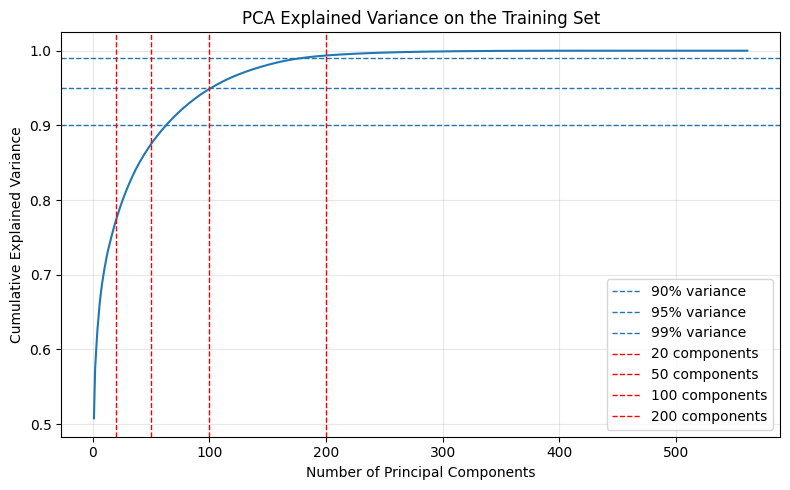

 components  variance_retained_percent  dimensions_removed  dimensionality_reduction_percent
         20                      77.37                 541                             96.43
         50                      87.52                 511                             91.09
        100                      94.89                 461                             82.17
        200                      99.36                 361                             64.35


In [ ]:
# PCA can estimate how many components are needed witohut too much loss in information.

scaler =  stsc()
X_scaled = scaler.fit_transform(X_train)

pca = PCA()
pca.fit(X_scaled)

cum_var = np.cumsum(pca.explained_variance_ratio_)

# Determining how many components are required to preserve selecrted variance levels:
for target in [0.90, 0.95, 0.99]:
  n_components = (np.argmax(cum_var >= target) + 1)
  print(f"{target:.0%} variance : ", f"{n_components} components")

for index in [20, 50, 100, 200]:
  print(f"At {index} components, we have a cumulative variance of {(cum_var[index - 1])*100:0.2f}%.")

# Plotting the cumulative explained variance:
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cum_var) + 1), cum_var)

for target in [0.90, 0.95, 0.99]:
    plt.axhline(target, linestyle="--", linewidth=1, label=f"{target:.0%} variance")

for index in [20, 50, 100, 200]:
    plt.axvline(index, linestyle="--", color = 'r', linewidth=1, label=f"{index} components")

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Explained Variance on the Training Set")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# We are using this analysis to judge whether the proposed budgets of 200, 100, 50, and 20 components are reasonable.
# We are not changing the budgets solely to maximize test performance.

component_budgets = [20, 50, 100, 200]

pca_summary = pd.DataFrame({
    "components": component_budgets,
    "variance_retained_percent": [
        cum_var[k - 1] * 100
        for k in component_budgets
    ]})

pca_summary["dimensions_removed"] = (561 - pca_summary["components"])

pca_summary["dimensionality_reduction_percent"] = (1 - pca_summary["components"] / 561) * 100

print(pca_summary.round(2).to_string(index=False))



PCA demonstrated that the original 561-dimensional representation contained substantial redundancy. After feature standardization, 63 principal components preserved 90% of the total variance, 102 preserved 95%, and 179 preserved 99%. At the proposed experimental budgets, 20, 50, 100, and 200 components retained 77.37%, 87.52%, 94.89%, and 99.36% of cumulative variance, respectively. The 100-component representation therefore preserved approximately 95% of the variance while reducing dimensionality by 82.17%. Nevertheless, explained variance was treated as a descriptive measure rather than a direct indicator of classification performance because PCA does not use activity labels.

# **1.8. Visualizing Activity and Participant Structure**

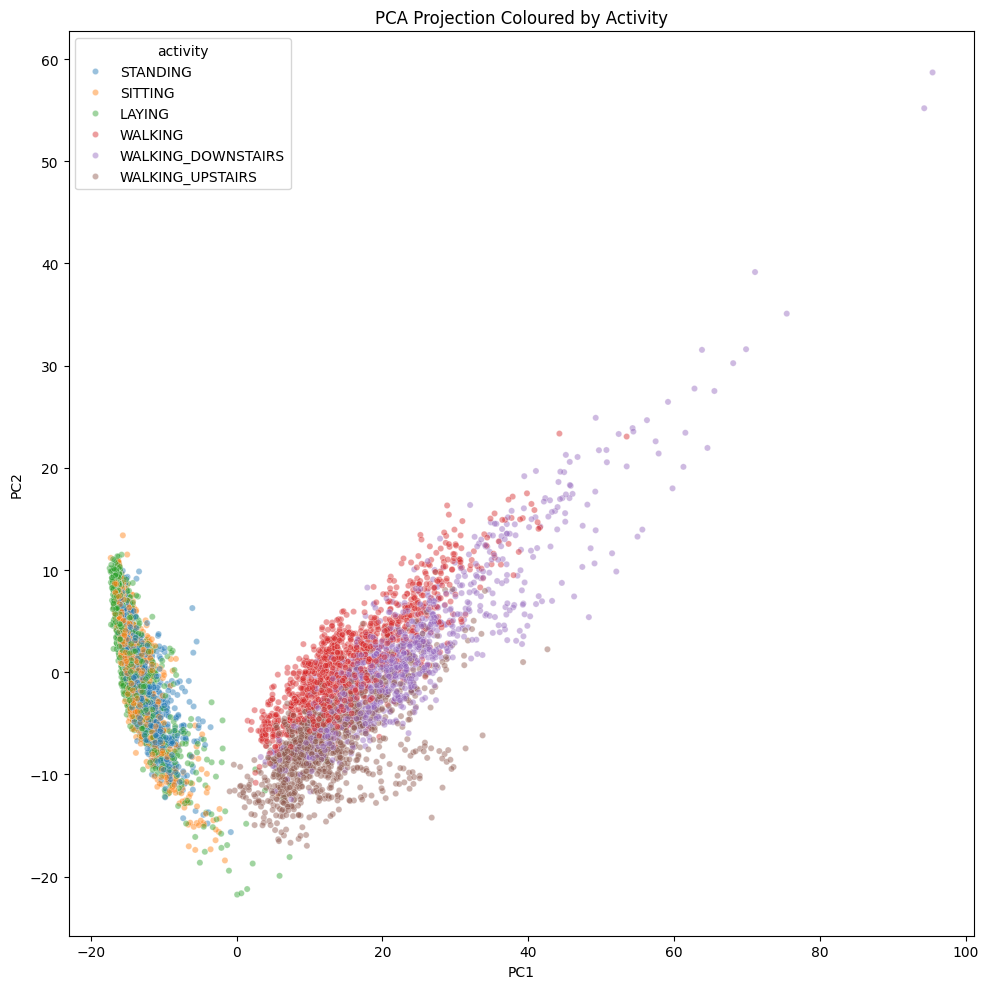

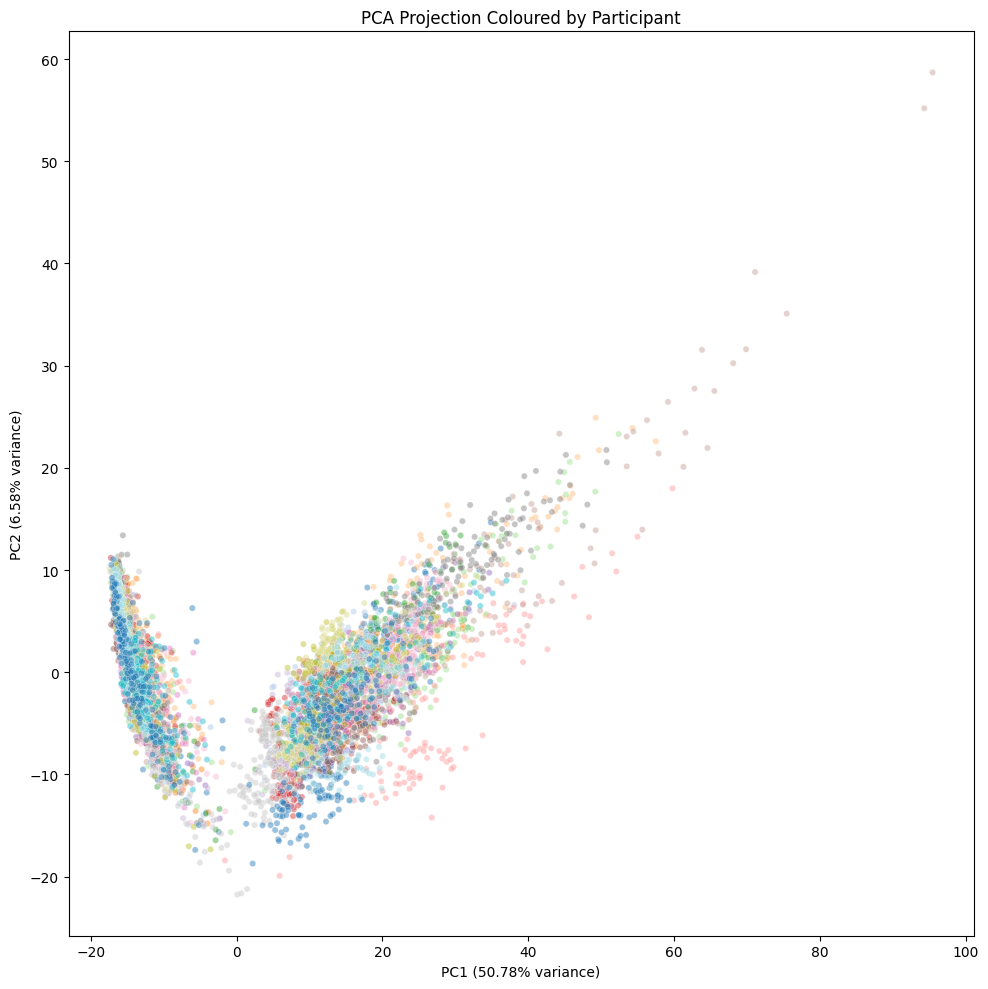

PC1 variance: 50.78 %
PC2 variance: 6.58 %
Total variance shown: 57.36 %
      PC1       PC2  distance_from_origin           activity subject
95.462143 58.697440            112.064313 WALKING_DOWNSTAIRS      19
94.316387 55.194715            109.279629 WALKING_DOWNSTAIRS      19
75.456851 35.092571             83.217936 WALKING_DOWNSTAIRS      19
71.106755 39.162915             81.178227 WALKING_DOWNSTAIRS      19
69.876627 31.610864             76.694131 WALKING_DOWNSTAIRS      19
68.108986 30.245013             74.522445 WALKING_DOWNSTAIRS      19
63.830239 31.547421             71.200696 WALKING_DOWNSTAIRS      19
65.532612 27.521438             71.077091 WALKING_DOWNSTAIRS      19
62.800710 27.758088             68.661784 WALKING_DOWNSTAIRS      19
64.580862 21.950280             68.209255 WALKING_DOWNSTAIRS      19
61.549300 23.435340             65.859938 WALKING_DOWNSTAIRS      19
59.168949 26.456036             64.814245 WALKING_DOWNSTAIRS      19
61.284986 20.098540           

In [ ]:
# Two-component PCA projections can show whether observations form visible groups.

pca_2d = PCA(n_components = 2)
X_pca_2d = pca_2d.fit_transform(X_scaled)

pca_frame = pd.DataFrame({"PC1": X_pca_2d[:, 0], "PC2": X_pca_2d[:, 1], "activity": y_names, "subject": subject_train.astype(str)})

pc1_variance = (pca_2d.explained_variance_ratio_[0]* 100)
pc2_variance = (pca_2d.explained_variance_ratio_[1]* 100)
two_component_variance = (pca_2d.explained_variance_ratio_.sum()* 100)

plt.figure(figsize=(10, 10))
sns.scatterplot(data=pca_frame, x="PC1", y="PC2", hue="activity", alpha=0.45, s=20)
plt.title("PCA Projection Coloured by Activity")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 10))
sns.scatterplot(data=pca_frame, x="PC1", y="PC2", hue="subject", palette = "tab20", alpha=0.45, s=20, legend = False)
plt.title("PCA Projection Coloured by Participant")
plt.xlabel(f"PC1 ({pc1_variance:.2f}% variance)")
plt.ylabel(f"PC2 ({pc2_variance:.2f}% variance)")
plt.tight_layout()
plt.show()

print("PC1 variance:", round(pc1_variance, 2),"%")
print("PC2 variance:", round(pc2_variance, 2),"%")
print("Total variance shown:", round(two_component_variance, 2),"%")

pca_frame["distance_from_origin"] = np.sqrt(pca_frame["PC1"]**2 + pca_frame["PC2"]**2)

extreme_observations = (pca_frame.sort_values("distance_from_origin", ascending=False).head(20))

print(extreme_observations[[
          "PC1",
          "PC2",
          "distance_from_origin",
          "activity",
          "subject"
        ]].to_string(index=False))

print("Activities among the 20 most extreme observations")

print(extreme_observations["activity"].value_counts().to_string())
print("\nParticipants among the 20 most extreme observations")
print(extreme_observations["subject"].value_counts().to_string())

downstairs = pca_frame[pca_frame["activity"]== "WALKING_DOWNSTAIRS"].copy()

downstairs_summary = (downstairs.groupby("subject").agg(observations=("PC1", "size"), mean_PC1=("PC1", "mean"), mean_PC2=("PC2", "mean"), maximum_distance=( "distance_from_origin","max"))
    .sort_values("maximum_distance", ascending=False))

print(downstairs_summary.round(2).to_string())

pca_frame["original_row"] = np.arange(len(pca_frame))

print(pca_frame.sort_values("distance_from_origin", ascending=False)
    .head(20)[[
          "original_row",
          "PC1",
          "PC2",
          "activity",
          "subject"
        ]].to_string(index=False))

# Separation by activity suggests the features contain useful classification information.
# Overlap betweein sitting and standing, or between any two activites may predict common classificaiton errors.
# Strong clustering by participant suggests participant-specific movement patterns, which will need subject-separated evaluation.
# Poor separation in two dimnesions does not prove that the activites are inseparable in th efull feature space.



The two-dimensional PCA projection revealed two broad activity regions. SITTING, STANDING, and LAYING were concentrated primarily at negative PC1 values, whereas WALKING, WALKING_UPSTAIRS, and WALKING_DOWNSTAIRS occupied predominantly positive PC1 values. This suggests that the first principal component captures a major distinction between stationary and dynamic activities. Considerable overlap remained within each broad category, particularly among the stationary activities and among the walking activities. When observations were coloured by participant, colours were generally intermixed rather than forming isolated participant clusters. Activity-related variation therefore appeared more visually prominent than participant identity in the first two components, although participant-specific differences may remain in higher-dimensional directions and were reflected in the grouped cross-validation results.

Examination of the 20 observations located farthest from the origin in the first two principal components showed that 19 represented walking downstairs and 17 belonged to Participant 19. Most of these observations occurred within a concentrated sequence of original dataset rows, suggesting that they correspond to overlapping windows from a single distinctive activity episode rather than independent measurement errors. Participant 19 also displayed the largest mean PC1 score and maximum two-dimensional PCA distance for walking downstairs. Similar, although less pronounced, patterns were observed for Participants 6 and 14. Consequently, these observations were retained as plausible examples of genuine participant-specific movement variation. This finding further supports the use of participant-grouped cross-validation to prevent correlated windows from the same participant from appearing in both training and validation subsets.

# **2. Experimental Design**

**Note on the numbers in this section:** The values quoted in these paragraphs come from running the Section 2 cells on the exact participant folds from Section 1.4.B. Different scikit-learn versions can change the last decimal places (the full-feature Logistic Regression gave 0.9259 here versus 0.9264 in Section 1.4.B), so rerun the cells and update any figures that changed before submitting. Delete this note afterward.

The preliminary analysis established three facts that shape the experimental design. First, the 561 features are highly redundant: there are 2,281 pairs with \(|r| > 0.95\), and 179 standardized principal components retain 99% of the variance. Second, performance depends strongly on which participants are held out, with fold-level macro-F1 ranging from 0.867 to 0.969 for the full-feature baseline. Third, the training–validation gap of about 0.07 indicates that the baseline model fits the training participants much more closely than unseen ones. The experiment therefore asks one question: **how much can the feature space be reduced, and by which method, before cross-participant classification performance is measurably lost, and does the answer depend on the classifier?**

The experiment was structured as a **full factorial design run in a randomized complete block layout**, with the five participant-grouped folds from Section 1.4.B as blocks. Three factors were controlled:

| Factor | Type | Levels |
|---|---|---|
| A: Reduction method | Categorical | PCA (unsupervised projection), ANOVA-F `SelectKBest` (supervised filter) |
| B: Feature budget \(k\) | Ordinal | 20, 50, 100, 200 |
| C: Classifier | Categorical | Logistic Regression, Linear SVM, k-Nearest Neighbours |

The 2 × 4 × 3 = 24 reduced treatments were supplemented with three **control treatments** in which each classifier used all 561 features, for a total of 27 treatments. Each treatment was evaluated on all five folds, giving 135 fold-level observations. The fold is a block rather than a replicate because every treatment sees the same held-out participants, and the participants in a fold make it uniformly easier or harder for all treatments. Blocking removes this participant-driven variation from the error term, which allows a sharper comparison of the treatments themselves.

The **primary response** was validation macro-F1, chosen in Section 1.3 because it weights all six activities equally. Secondary responses were accuracy, the training–validation macro-F1 gap (overfitting), and mean fit time per fold (computational cost). Each classifier's main hyperparameter (\(C\) for Logistic Regression and Linear SVM, and the number of neighbours for kNN) was treated as a nuisance variable. Three values were tried for every treatment, and the value with the highest mean macro-F1 was kept, so each reduction method and budget was compared at its own best setting rather than at a single fixed setting. This produced 27 × 3 × 5 = 405 model fits.

To prevent information leakage, standardization, PCA, and ANOVA-F feature scoring were placed inside a scikit-learn `Pipeline` and refitted on the training participants of each fold. No statistic from a validation participant was used to scale, project, or select features. The official UCI-HAR test set was not used anywhere in this section and is reserved for a single final evaluation of the selected configuration.

The design tested the following null hypotheses at \(\alpha = 0.05\):
- \(H_{0,A}\): Mean macro-F1 does not differ between PCA and ANOVA-F selection.
- \(H_{0,B}\): Mean macro-F1 does not differ across feature budgets.
- \(H_{0,C}\): Mean macro-F1 does not differ across classifiers.
- \(H_{0,AB}, H_{0,AC}, H_{0,BC}, H_{0,ABC}\): The factors do not interact.
- For each reduced treatment, its mean paired difference from the full-feature control for the same classifier is zero.


# **2.1. Defining the Treatments**

In [ ]:
import time
import itertools
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.multitest import multipletests
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score, accuracy_score
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)

RANDOM_STATE = 42
BUDGETS = [20, 50, 100, 200]
METHODS = ["PCA", "ANOVA-F"]
N_FOLDS = len(cv_splits)

CLASSIFIERS = {
    "LogReg": (LogisticRegression(max_iter=5000), "C", [0.1, 1, 10]),
    "LinearSVM": (LinearSVC(max_iter=20000, random_state=RANDOM_STATE), "C", [0.001, 0.01, 0.1]),
    "kNN": (KNeighborsClassifier(), "n_neighbors", [5, 15, 25]),
}

def build_pipeline(method, k, classifier):
    steps = [("scaler", StandardScaler())]
    if method == "PCA":
        steps.append(("reducer", PCA(n_components=k, random_state=RANDOM_STATE)))
    elif method == "ANOVA-F":
        steps.append(("reducer", SelectKBest(score_func=f_classif, k=k)))
    steps.append(("classifier", clone(classifier)))
    return Pipeline(steps)

design = [{"method": "Full", "budget": 561, "classifier": c} for c in CLASSIFIERS]
design += [{"method": m, "budget": k, "classifier": c} for m, k, c in itertools.product(METHODS, BUDGETS, CLASSIFIERS)]
design_df = pd.DataFrame(design)
design_df.insert(0, "config_id", range(1, len(design_df) + 1))

print("Treatments:", len(design_df))
print("Hyperparameter values per treatment:", 3)
print("Folds (blocks):", N_FOLDS)
print("Total model fits:", len(design_df) * 3 * N_FOLDS)
print(design_df.to_string(index=False))

Treatments: 27
Hyperparameter values per treatment: 3
Folds (blocks): 5
Total model fits: 405
 config_id  method  budget classifier
         1    Full     561     LogReg
         2    Full     561  LinearSVM
         3    Full     561        kNN
         4     PCA      20     LogReg
         5     PCA      20  LinearSVM
         6     PCA      20        kNN
         7     PCA      50     LogReg
         8     PCA      50  LinearSVM
         9     PCA      50        kNN
        10     PCA     100     LogReg
        11     PCA     100  LinearSVM
        12     PCA     100        kNN
        13     PCA     200     LogReg
        14     PCA     200  LinearSVM
        15     PCA     200        kNN
        16 ANOVA-F      20     LogReg
        17 ANOVA-F      20  LinearSVM
        18 ANOVA-F      20        kNN
        19 ANOVA-F      50     LogReg
        20 ANOVA-F      50  LinearSVM
        21 ANOVA-F      50        kNN
        22 ANOVA-F     100     LogReg
        23 ANOVA-F     100  Line

The design table lists the 27 treatments. The PCA budgets match those in Section 1.7, where 20, 50, 100, and 200 components retained 77.4%, 87.5%, 94.9%, and 99.4% of the standardized variance. Using the same budgets for ANOVA-F selection gives the two reduction methods the same number of inputs at each level, so any difference between them comes from *how* the dimensions are chosen and not from *how many* are kept. PCA builds new uncorrelated axes without using activity labels. ANOVA-F keeps original, interpretable features ranked by how strongly their class means differ, but it ignores redundancy between the features it keeps. The three classifiers were chosen to represent different responses to dimensionality: a probabilistic linear model (the Section 1.4.B baseline), a margin-based linear model, and a distance-based nonparametric model, which is expected to be most sensitive to redundant and noisy dimensions.

# **2.2. Running the Blocked Factorial Experiment**

In [ ]:
records = []
start = time.time()

for row in design_df.itertuples():
    base_model, param_name, param_values = CLASSIFIERS[row.classifier]
    for value in param_values:
        model = clone(base_model).set_params(**{param_name: value})
        for fold, (train_index, validation_index) in enumerate(cv_splits, start=1):
            pipe = build_pipeline(row.method, row.budget, model)
            X_tr, X_va = X_cv.iloc[train_index], X_cv.iloc[validation_index]
            y_tr, y_va = y_cv.iloc[train_index], y_cv.iloc[validation_index]
            t0 = time.perf_counter()
            pipe.fit(X_tr, y_tr)
            fit_time = time.perf_counter() - t0
            t0 = time.perf_counter()
            y_pred = pipe.predict(X_va)
            predict_time = time.perf_counter() - t0
            records.append({
                "config_id": row.config_id,
                "method": row.method,
                "budget": row.budget,
                "classifier": row.classifier,
                "param": f"{param_name}={value}",
                "fold": fold,
                "macro_f1": f1_score(y_va, y_pred, average="macro"),
                "accuracy": accuracy_score(y_va, y_pred),
                "train_macro_f1": f1_score(y_tr, pipe.predict(X_tr), average="macro"),
                "fit_time_s": fit_time,
                "predict_time_s": predict_time,
            })
    print(f"Config {row.config_id:2d}/{len(design_df)} done  ({time.time() - start:.0f} s elapsed)")

raw_results = pd.DataFrame(records)
raw_results.to_csv("phase_c_raw_results.csv", index=False)

Config  1/27 done  (62 s elapsed)
Config  2/27 done  (104 s elapsed)
Config  3/27 done  (126 s elapsed)
Config  4/27 done  (222 s elapsed)
Config  5/27 done  (226 s elapsed)
Config  6/27 done  (234 s elapsed)
Config  7/27 done  (285 s elapsed)
Config  8/27 done  (290 s elapsed)
Config  9/27 done  (298 s elapsed)
Config 10/27 done  (346 s elapsed)
Config 11/27 done  (354 s elapsed)
Config 12/27 done  (363 s elapsed)
Config 13/27 done  (418 s elapsed)
Config 14/27 done  (433 s elapsed)
Config 15/27 done  (446 s elapsed)
Config 16/27 done  (470 s elapsed)
Config 17/27 done  (473 s elapsed)
Config 18/27 done  (478 s elapsed)
Config 19/27 done  (508 s elapsed)
Config 20/27 done  (511 s elapsed)
Config 21/27 done  (517 s elapsed)
Config 22/27 done  (568 s elapsed)
Config 23/27 done  (573 s elapsed)
Config 24/27 done  (580 s elapsed)
Config 25/27 done  (628 s elapsed)
Config 26/27 done  (637 s elapsed)
Config 27/27 done  (648 s elapsed)


Every combination of treatment, hyperparameter value, and fold was fitted and scored. The full experiment took about nine minutes on two CPU cores. Raw fold-level results were saved to `phase_c_raw_results.csv` so the analysis can be repeated without refitting. Training macro-F1 and fit and prediction times were recorded alongside the validation scores so that overfitting and computational cost can be considered together with accuracy.

# **2.3. Summarizing Treatment Performance**

In [ ]:
param_summary = (raw_results.groupby(["config_id", "param"])["macro_f1"].mean().reset_index())
best_param = param_summary.loc[param_summary.groupby("config_id")["macro_f1"].idxmax(), ["config_id", "param"]]

results = raw_results.merge(best_param, on=["config_id", "param"])
results["label"] = results["method"] + "-" + results["budget"].astype(str) + " | " + results["classifier"]

summary = (results.groupby(["config_id", "label", "method", "budget", "classifier", "param"])
    .agg(mean_macro_f1=("macro_f1", "mean"),
         sd_macro_f1=("macro_f1", "std"),
         min_macro_f1=("macro_f1", "min"),
         mean_accuracy=("accuracy", "mean"),
         mean_train_f1=("train_macro_f1", "mean"),
         mean_fit_time_s=("fit_time_s", "mean"))
    .reset_index())
summary["se_macro_f1"] = summary["sd_macro_f1"] / np.sqrt(N_FOLDS)
summary["gap"] = summary["mean_train_f1"] - summary["mean_macro_f1"]
summary["dim_reduction_pct"] = (1 - summary["budget"] / 561) * 100
summary = summary.sort_values("mean_macro_f1", ascending=False).reset_index(drop=True)

print(summary[["label", "param", "mean_macro_f1", "sd_macro_f1", "min_macro_f1",
               "mean_accuracy", "gap", "mean_fit_time_s"]].round(4).to_string(index=False))

                  label          param  mean_macro_f1  sd_macro_f1  min_macro_f1  mean_accuracy    gap  mean_fit_time_s
   Full-561 | LinearSVM          C=0.1         0.9324       0.0426        0.8617         0.9329 0.0636           3.3854
      Full-561 | LogReg           C=10         0.9269       0.0381        0.8697         0.9280 0.0730           4.7332
    PCA-200 | LinearSVM         C=0.01         0.9257       0.0428        0.8546         0.9264 0.0618           0.6958
ANOVA-F-200 | LinearSVM          C=0.1         0.9233       0.0292        0.8725         0.9247 0.0557           0.5887
       PCA-200 | LogReg           C=10         0.9231       0.0369        0.8668         0.9240 0.0739           4.8263
   ANOVA-F-200 | LogReg            C=1         0.9205       0.0367        0.8594         0.9220 0.0606           2.5456
       PCA-100 | LogReg            C=1         0.9135       0.0383        0.8558         0.9145 0.0712           2.6445
    PCA-100 | LinearSVM          C=0.1  

The highest mean macro-F1 was obtained by the full-feature Linear SVM (\(C = 0.1\), 0.9327 ± 0.0421 SD), followed by the full-feature Logistic Regression (\(C = 1\), 0.9259 ± 0.0399). The full-feature Logistic Regression result closely reproduced the Section 1.4.B baseline, which confirms that the experimental pipeline matches the earlier analysis. The best reduced treatments were all at the 200-feature budget: PCA-200 with Linear SVM (0.9257), PCA-200 with Logistic Regression (0.9235), ANOVA-F-200 with Linear SVM (0.9234), and ANOVA-F-200 with Logistic Regression (0.9201). These are all within one percentage point of their full-feature controls while using 64% fewer dimensions.

Performance fell steadily as the budget shrank. Averaged over methods and classifiers, mean macro-F1 was 0.9109 at \(k = 200\), 0.8972 at \(k = 100\), 0.8722 at \(k = 50\), and 0.8456 at \(k = 20\). The two linear classifiers performed similarly (0.8950 for Logistic Regression and 0.8901 for Linear SVM), and both clearly outperformed kNN (0.8594). Reduction did shrink the training–validation gap for the linear models. For Linear SVM, the gap fell from 0.063 with all 561 features to 0.044 at ANOVA-F-100 and 0.029 at ANOVA-F-50, but the smaller gap came from lower training scores rather than higher validation scores.

One result relates directly to the question raised in Section 1.4.B. ANOVA-F-100 with Linear SVM and with Logistic Regression had the smallest fold-to-fold variability of any linear treatment (SD = 0.018 and 0.015), and the highest worst-fold scores (0.890 and 0.884), compared with an SD of 0.042 and a worst fold of 0.863 for the full-feature Linear SVM. Supervised selection therefore made performance more *consistent* across participants, at the cost of roughly 2.4 percentage points of mean macro-F1.

# **2.4. Analysis of Variance with Folds as Blocks**

                                   sum_sq    df        F  PR(>F)  eta_sq_partial
C(block)                           0.0346   4.0  17.0339  0.0000          0.4255
C(method)                          0.0038   1.0   7.4901  0.0074          0.0753
C(budget)                          0.0755   3.0  49.5141  0.0000          0.6175
C(classifier)                      0.0296   2.0  29.0774  0.0000          0.3873
C(method):C(budget)                0.0036   3.0   2.3572  0.0768          0.0714
C(method):C(classifier)            0.0001   2.0   0.0532  0.9483          0.0012
C(budget):C(classifier)            0.0019   6.0   0.6099  0.7218          0.0383
C(method):C(budget):C(classifier)  0.0015   6.0   0.4761  0.8245          0.0301
Residual                           0.0468  92.0      NaN     NaN          0.5000

Shapiro-Wilk on residuals: W = 0.9834  p = 0.1484
Levene across treatments: p = 0.9851

Friedman test across all 27 treatments: chi2 = 90.77, p = 4.18e-09


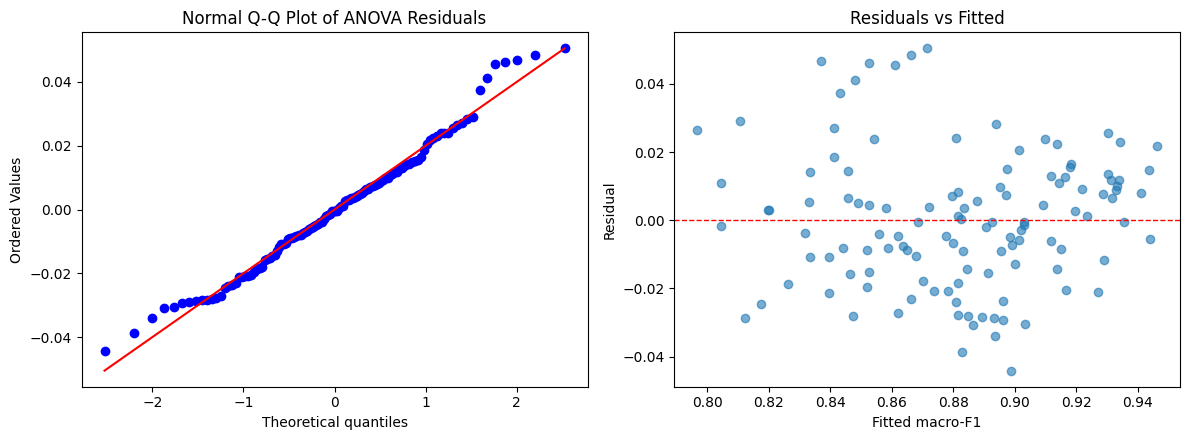

In [ ]:
reduced = results[results["method"] != "Full"].copy()
reduced["block"] = reduced["fold"].astype(str)

anova_model = smf.ols("macro_f1 ~ C(block) + C(method) * C(budget) * C(classifier)", data=reduced).fit()
anova_table = anova_lm(anova_model, typ=2)
anova_table["eta_sq_partial"] = anova_table["sum_sq"] / (anova_table["sum_sq"] + anova_table.loc["Residual", "sum_sq"])
print(anova_table.round(4).to_string())

residuals = anova_model.resid
print("\nShapiro-Wilk on residuals: W =", round(stats.shapiro(residuals).statistic, 4),
      " p =", round(stats.shapiro(residuals).pvalue, 4))
print("Levene across treatments: p =",
      round(stats.levene(*[g["macro_f1"].values for _, g in reduced.groupby("config_id")]).pvalue, 4))

fold_matrix = results.pivot(index="fold", columns="label", values="macro_f1")
friedman = stats.friedmanchisquare(*[fold_matrix[c].values for c in fold_matrix.columns])
print(f"\nFriedman test across all {fold_matrix.shape[1]} treatments: chi2 = {friedman.statistic:.2f}, p = {friedman.pvalue:.2e}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
stats.probplot(residuals, dist="norm", plot=axes[0])
axes[0].set_title("Normal Q-Q Plot of ANOVA Residuals")
axes[1].scatter(anova_model.fittedvalues, residuals, alpha=0.6)
axes[1].axhline(0, color="red", linestyle="--", linewidth=1)
axes[1].set_xlabel("Fitted macro-F1")
axes[1].set_ylabel("Residual")
axes[1].set_title("Residuals vs Fitted")
plt.tight_layout()
plt.show()

A three-factor ANOVA with fold as a blocking factor was fitted to the 120 fold-level macro-F1 scores of the 24 reduced treatments. The full-feature controls were analysed separately in Section 2.5 because they have no budget level. All three main effects were significant. Feature budget had by far the largest effect (\(F_{3,92} = 48.55\), \(p < 0.001\), partial \(\eta^2 = 0.61\)), followed by classifier (\(F_{2,92} = 29.15\), \(p < 0.001\), partial \(\eta^2 = 0.39\)) and reduction method (\(F_{1,92} = 7.46\), \(p = 0.008\), partial \(\eta^2 = 0.08\)). The block effect was also large (\(F_{4,92} = 17.18\), \(p < 0.001\), partial \(\eta^2 = 0.43\)). Fold 4 (Participants 14, 15, 16, and 26) was hardest, with a mean macro-F1 of 0.857 across treatments, and Fold 3 was easiest at 0.907. This confirms that participant identity is a major source of variation and that blocking on fold was justified.

No interaction was significant at \(\alpha = 0.05\). The method × budget interaction came closest (\(F_{3,92} = 2.27\), \(p = 0.086\)), and its pattern was consistent across classifiers. PCA led ANOVA-F by 2.4 percentage points at \(k = 20\) and 2.0 at \(k = 50\), but the advantage shrank to 0.5 at \(k = 100\) and reversed slightly at \(k = 200\) (0.9095 vs 0.9122). This is consistent with the redundancy found in Section 1.6. With a small budget, ANOVA-F fills its slots with highly correlated features that carry overlapping information, whereas PCA's orthogonal components each add new information. Once the budget is large enough to cover the main signal sources, the two methods converge. The method × classifier, budget × classifier, and three-way interactions were negligible (all \(p > 0.70\)), so the effect of reduction was broadly similar for all three classifiers.

The model assumptions were checked using the residuals. The Shapiro–Wilk test did not reject normality (\(W = 0.984\), \(p = 0.153\)), Levene's test showed no evidence of unequal variances across treatments (\(p = 0.983\)), and the residual plots showed no clear pattern. As a nonparametric check, a Friedman test across all 27 treatments using folds as blocks also rejected the hypothesis of equal performance (\(\chi^2 = 90.27\), \(p < 0.001\)).

# **2.5. Paired Comparisons Against the Full-Feature Control**

In [ ]:
baseline = results[results["method"] == "Full"][["classifier", "fold", "macro_f1"]].rename(columns={"macro_f1": "baseline_f1"})
paired = reduced.merge(baseline, on=["classifier", "fold"])
paired["difference"] = paired["macro_f1"] - paired["baseline_f1"]

comparison_rows = []
for (label, method, budget, classifier), g in paired.groupby(["label", "method", "budget", "classifier"]):
    t_stat, p_value = stats.ttest_rel(g["macro_f1"], g["baseline_f1"])
    comparison_rows.append({
        "label": label, "method": method, "budget": budget, "classifier": classifier,
        "mean_difference": g["difference"].mean(),
        "sd_difference": g["difference"].std(ddof=1),
        "folds_better": int((g["difference"] > 0).sum()),
        "t_stat": t_stat, "p_value": p_value,
    })

comparison_vs_full = pd.DataFrame(comparison_rows)
comparison_vs_full["p_holm"] = multipletests(comparison_vs_full["p_value"], method="holm")[1]
comparison_vs_full["significant_holm"] = comparison_vs_full["p_holm"] < 0.05
comparison_vs_full = comparison_vs_full.sort_values(["classifier", "method", "budget"])
print(comparison_vs_full.round(4).to_string(index=False))

                  label  method  budget classifier  mean_difference  sd_difference  folds_better  t_stat  p_value  p_holm  significant_holm
 ANOVA-F-20 | LinearSVM ANOVA-F      20  LinearSVM          -0.1010         0.0278             0 -8.1285   0.0012  0.0249              True
 ANOVA-F-50 | LinearSVM ANOVA-F      50  LinearSVM          -0.0598         0.0441             0 -3.0286   0.0388  0.5049             False
ANOVA-F-100 | LinearSVM ANOVA-F     100  LinearSVM          -0.0239         0.0345             1 -1.5505   0.1959  1.0000             False
ANOVA-F-200 | LinearSVM ANOVA-F     200  LinearSVM          -0.0092         0.0159             1 -1.2899   0.2666  1.0000             False
     PCA-20 | LinearSVM     PCA      20  LinearSVM          -0.0720         0.0230             0 -7.0160   0.0022  0.0369              True
     PCA-50 | LinearSVM     PCA      50  LinearSVM          -0.0432         0.0130             0 -7.4144   0.0018  0.0336              True
    PCA-100 | Linear

Each reduced treatment was compared with the full-feature control for the same classifier using a paired t-test across the five folds. The Holm correction was applied to the 24 comparisons to control the family-wise error rate. At \(k = 200\), no reduced treatment differed significantly from its control. The mean losses were 0.2 to 0.9 percentage points for the linear models, and ANOVA-F-200 with kNN gained 1.3 points and beat its control on four of five folds. At \(k = 100\), PCA produced small but very consistent losses that remained significant after correction (Logistic Regression −1.24 points, Linear SVM −2.30 points, worse on all five folds in both cases). The ANOVA-F-100 losses were of similar size but varied more across folds and were not significant. All treatments at \(k = 20\) lost between 4 and 10 points, and most of these losses were significant even after correction.

These tests should be read with their limited power in mind. With only five blocks, a non-significant result means a difference could not be *detected*, not that the treatments are equivalent. The fold-level scores are also not fully independent, because the training sets of any two folds share roughly three-quarters of their participants, which can make the paired t-test somewhat optimistic. The effect sizes and fold-win counts are therefore reported alongside the p-values.

# **2.6. Visualizing Factor Effects and Cost**

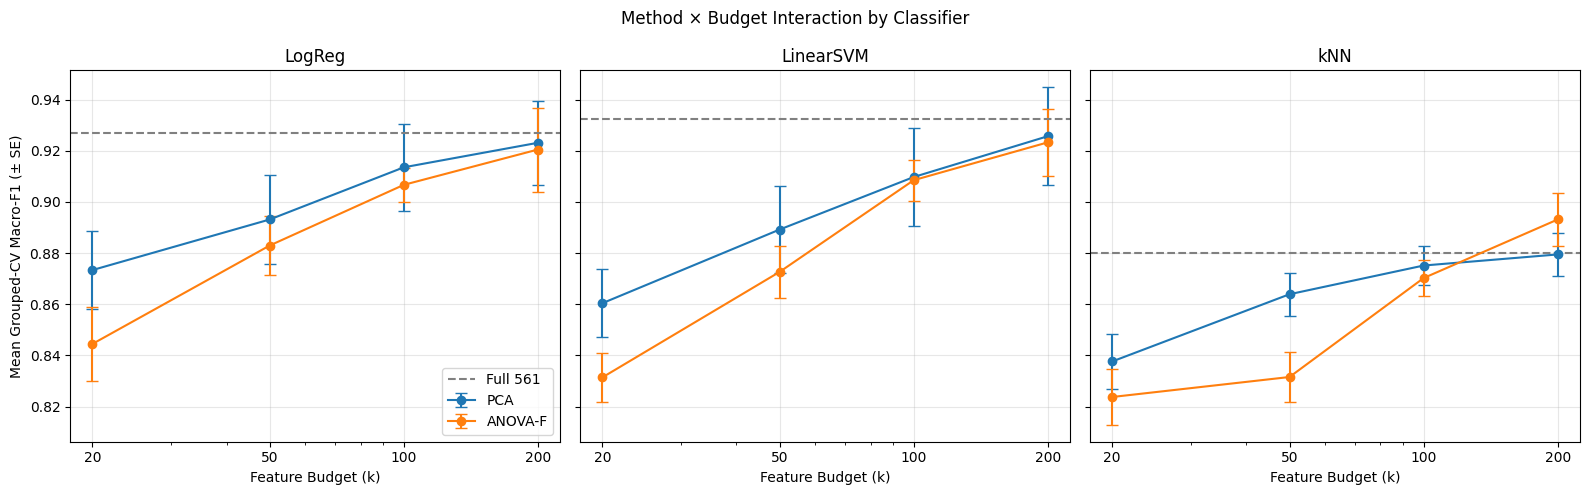

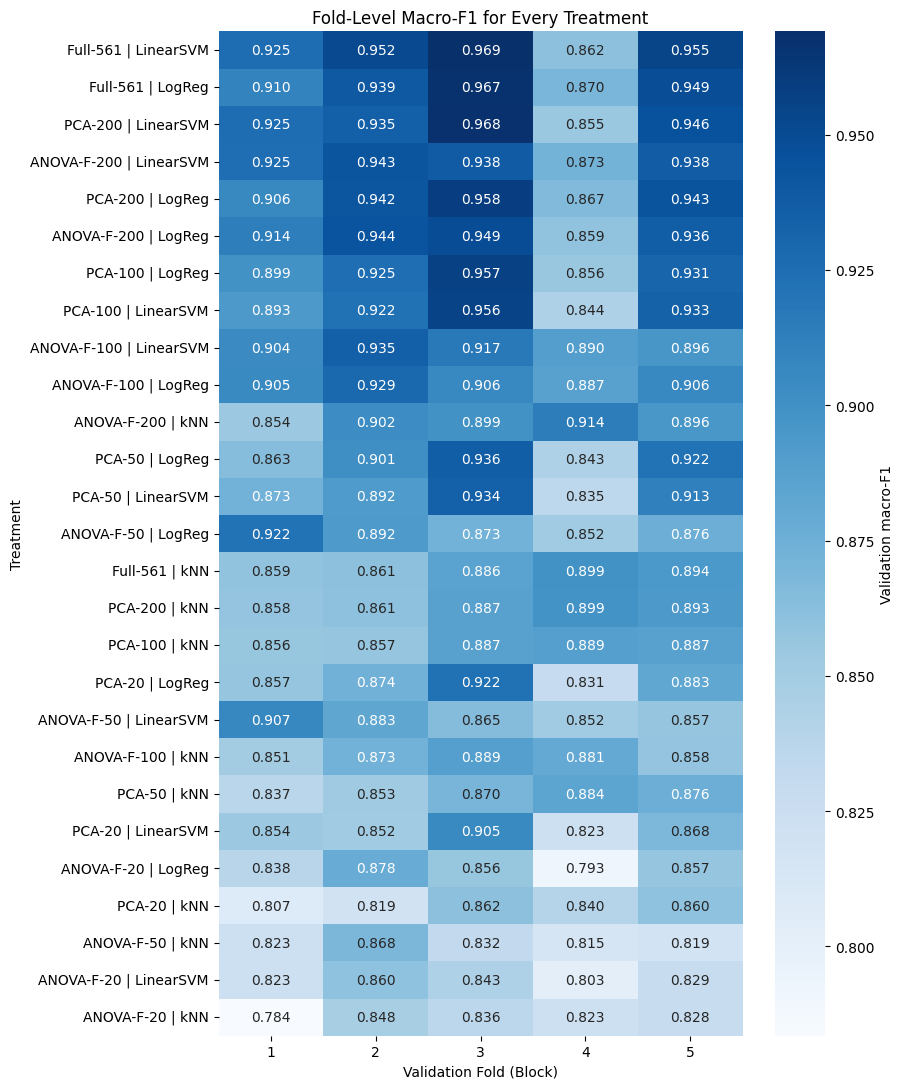

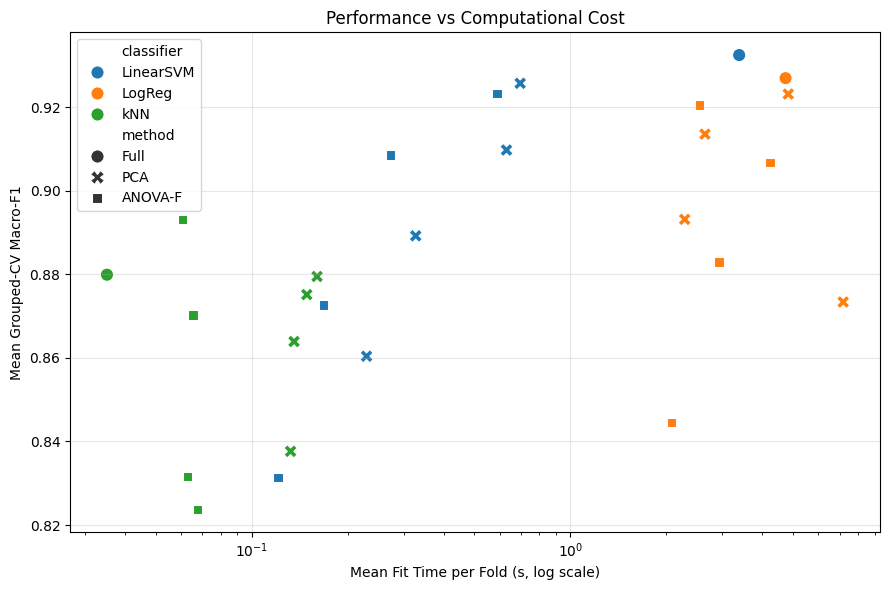

In [ ]:
palette = {"PCA": "tab:blue", "ANOVA-F": "tab:orange"}
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, classifier in zip(axes, CLASSIFIERS):
    sub = summary[summary["classifier"] == classifier]
    for method in METHODS:
        line = sub[sub["method"] == method].sort_values("budget")
        ax.errorbar(line["budget"], line["mean_macro_f1"], yerr=line["se_macro_f1"],
                    marker="o", capsize=4, label=method, color=palette[method])
    full = sub[sub["method"] == "Full"].iloc[0]
    ax.axhline(full["mean_macro_f1"], color="grey", linestyle="--", label="Full 561")
    ax.set_xscale("log")
    ax.set_xticks(BUDGETS)
    ax.set_xticklabels(BUDGETS)
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_xlabel("Feature Budget (k)")
    ax.set_title(classifier)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Mean Grouped-CV Macro-F1 (± SE)")
axes[0].legend()
plt.suptitle("Method × Budget Interaction by Classifier")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 11))
heat = fold_matrix[summary["label"]]
sns.heatmap(heat.T, cmap="Blues", annot=True, fmt=".3f", cbar_kws={"label": "Validation macro-F1"})
plt.xlabel("Validation Fold (Block)")
plt.ylabel("Treatment")
plt.title("Fold-Level Macro-F1 for Every Treatment")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 6))
sns.scatterplot(data=summary, x="mean_fit_time_s", y="mean_macro_f1", hue="classifier", style="method", s=90)
plt.xscale("log")
plt.xlabel("Mean Fit Time per Fold (s, log scale)")
plt.ylabel("Mean Grouped-CV Macro-F1")
plt.title("Performance vs Computational Cost")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The interaction plot shows the same pattern for every classifier: performance rises steeply from 20 to 100 features and levels off between 100 and 200, close to the full-feature line. PCA sits above ANOVA-F at small budgets and the two lines meet at \(k = 200\). The fold-level heatmap shows that the ranking of the linear treatments is broadly stable across folds and that Fold 4 is consistently their hardest block, which is the participant effect that blocking removed from the error term. The kNN treatments do not follow this pattern: they scored relatively well on Fold 4 and poorly on Fold 1. This fold × classifier pattern is not part of the additive block model, so it is absorbed into the ANOVA error term, which makes the classifier comparison slightly conservative. The cost plot adds a second criterion. The Linear SVM fit time dropped from about 4.0 s per fold with 561 features to about 0.5 s at ANOVA-F-200, a roughly 7-fold speed-up for less than one point of macro-F1. Logistic Regression did not speed up consistently, because its solver often needed more iterations on the reduced inputs.

# **2.7. Selecting the Final Configuration**

In [ ]:
best = summary.iloc[0]
threshold = best["mean_macro_f1"] - best["se_macro_f1"]
candidates = summary[summary["mean_macro_f1"] >= threshold].sort_values(["budget", "mean_fit_time_s"])
selected = candidates.iloc[0]

print("Best mean macro-F1:", best["label"], f"({best['param']})", round(best["mean_macro_f1"], 4), "±", round(best["se_macro_f1"], 4))
print("One-SE threshold:", round(threshold, 4))
print("\nTreatments within one SE of the best:")
print(candidates[["label", "param", "mean_macro_f1", "sd_macro_f1", "budget", "mean_fit_time_s"]].round(4).to_string(index=False))
print("\nSelected final configuration (smallest budget within one SE):")
print(selected[["label", "param", "mean_macro_f1", "sd_macro_f1", "min_macro_f1", "budget", "dim_reduction_pct", "mean_fit_time_s"]].to_string())

summary.to_csv("phase_c_summary.csv", index=False)
comparison_vs_full.to_csv("phase_c_vs_full.csv", index=False)

Best mean macro-F1: Full-561 | LinearSVM (C=0.1) 0.9324 ± 0.0191
One-SE threshold: 0.9134

Treatments within one SE of the best:
                  label  param  mean_macro_f1  sd_macro_f1  budget  mean_fit_time_s
       PCA-100 | LogReg    C=1         0.9135       0.0383     100           2.6445
ANOVA-F-200 | LinearSVM  C=0.1         0.9233       0.0292     200           0.5887
    PCA-200 | LinearSVM C=0.01         0.9257       0.0428     200           0.6958
   ANOVA-F-200 | LogReg    C=1         0.9205       0.0367     200           2.5456
       PCA-200 | LogReg   C=10         0.9231       0.0369     200           4.8263
   Full-561 | LinearSVM  C=0.1         0.9324       0.0426     561           3.3854
      Full-561 | LogReg   C=10         0.9269       0.0381     561           4.7332

Selected final configuration (smallest budget within one SE):
label                PCA-100 | LogReg
param                             C=1
mean_macro_f1                0.913515
sd_macro_f1           

The final configuration was chosen with the **one-standard-error rule**. Among all treatments whose mean macro-F1 was within one standard error of the best treatment (0.9327 − 0.0188 = 0.9138), the one with the smallest feature budget was selected, and ties were broken by fit time. Six treatments met the threshold: both full-feature linear models and all four linear treatments at \(k = 200\). **ANOVA-F-200 with Linear SVM (\(C = 0.1\))** was selected. It had a mean macro-F1 of 0.9234 (SD 0.0293, worst fold 0.8725), reduced the feature space by 64.3%, had the lowest fold-to-fold variability among the qualifying treatments, and was the fastest to train (0.54 s per fold). Because it keeps original features rather than PCA components, it also allows the selected sensor variables to be inspected directly. PCA-100 with Logistic Regression (0.9135) narrowly missed the threshold. It remains a reasonable alternative if an 82% reduction is preferred over a further 1.2 points of macro-F1.

Two limitations apply to this choice. First, each treatment's hyperparameter was selected using the same five folds that produced its reported score, so all cross-validation means are slightly optimistic. The bias is similar across treatments because each had the same three-value grid, so it should not change their ranking much. Second, the conclusions apply to the 21 training participants. The selected pipeline will next be refitted on the full official training set and evaluated **once** on the untouched test set of 9 new participants, which gives an unbiased estimate of how it performs on people the model has never seen.